mini project 3


In [ ]:
def generate_fibonacci_stock(n=15):
    """Generates the first n Fibonacci numbers as a baseline stock sequence."""
    fib_sequence = [0, 1]
    for _ in range(2, n):
        fib_sequence.append(fib_sequence[-1] + fib_sequence[-2])
    return fib_sequence


# Generate 15 Fibonacci stock levels
fib_stock = generate_fibonacci_stock(15)

# Display annual stock levels
print("Year | Fibonacci Stock Level (MT)")
print("-" * 32)
for year, stock in enumerate(fib_stock):
    print(f"{year:4d} | {stock:10d}")

Year | Fibonacci Stock Level (MT)
--------------------------------
   0 |          0
   1 |          1
   2 |          1
   3 |          2
   4 |          3
   5 |          5
   6 |          8
   7 |         13
   8 |         21
   9 |         34
  10 |         55
  11 |         89
  12 |        144
  13 |        233
  14 |        377


Explanation of Biological InaccuracyUnbounded Fibonacci growth assumes that population expansion depends solely on previous generations without environmental limits, causing the stock to grow exponentially at a rate approaching the golden ratio ($\phi \approx 1.618$). In actual aquatic ecosystems like Lake Victoria, biological growth is strictly constrained by carrying capacity ($K$), which limits available nutrients, oxygen, and spawning grounds. As fish density increases, density-dependent factors such as food scarcity, increased predation, and disease naturally slow net reproduction and raise mortality. Consequently, real fish populations follow logistic growth trajectories (S-curves) that level off near carrying capacity rather than expanding indefinitely toward infinity.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


class FishStock:

    def __init__(self, r=0.4, K=10000.0, N0=4000.0, h=0.0):
        """Discrete Logistic Growth Model with Harvesting.

        Parameters:
        - r : Intrinsic growth rate (default: 0.4)
        - K : Carrying capacity in tonnes (default: 10,000)
        - N0: Initial population stock in tonnes (default: 4,000)
        - h : Weekly harvest rate fraction [0.0 to 1.0] (default: 0.0)
        """
        self.r = r
        self.K = K
        self.N0 = N0
        self.h = h

    def simulate(self, weeks=52):
        """Simulates discrete population trajectories over a given number of weeks.

        Returns a pandas DataFrame containing week-by-week stock levels and
        harvests.
        """
        population = [self.N0]
        harvests = []

        for t in range(weeks):
            N_t = population[-1]
            harvest_t = self.h * N_t

            # Discrete Logistic Growth Equation with Harvesting:
            # N(t+1) = N(t) + r * N(t) * (1 - N(t) / K) - h * N(t)
            N_next = N_t + self.r * N_t * (1 - N_t / self.K) - harvest_t

            # Floor population at 0 to prevent negative stock values
            N_next = max(0.0, N_next)

            population.append(N_next)
            harvests.append(harvest_t)

        # Include final harvest at week 52 for array length matching
        harvests.append(self.h * population[-1])

        df = pd.DataFrame(
            {
                "Week": range(weeks + 1),
                "Population_N_t": population,
                "Harvest_tonnes": harvests,
            }
        )
        return df


# --- Execution Example ---
if __name__ == "__main__":
    # Baseline simulation with unharvested stock (h = 0.0)
    model_unharvested = FishStock(r=0.4, K=10000, N0=4000, h=0.0)
    df_results = model_unharvested.simulate(weeks=52)

    print("=== Simulation Results (Unharvested h=0.0) ===")
    print("First 5 Weeks:")
    print(df_results.head(5).to_string(index=False))
    print("\nLast 5 Weeks (Converging to K = 10,000 tonnes):")
    print(df_results.tail(5).to_string(index=False))

=== Simulation Results (Unharvested h=0.0) ===
First 5 Weeks:
 Week  Population_N_t  Harvest_tonnes
    0     4000.000000             0.0
    1     4960.000000             0.0
    2     5959.936000             0.0
    3     6923.076915             0.0
    4     7775.147922             0.0

Last 5 Weeks (Converging to K = 10,000 tonnes):
 Week  Population_N_t  Harvest_tonnes
   48     9999.999999             0.0
   49    10000.000000             0.0
   50    10000.000000             0.0
   51    10000.000000             0.0
   52    10000.000000             0.0


Graph for simulation

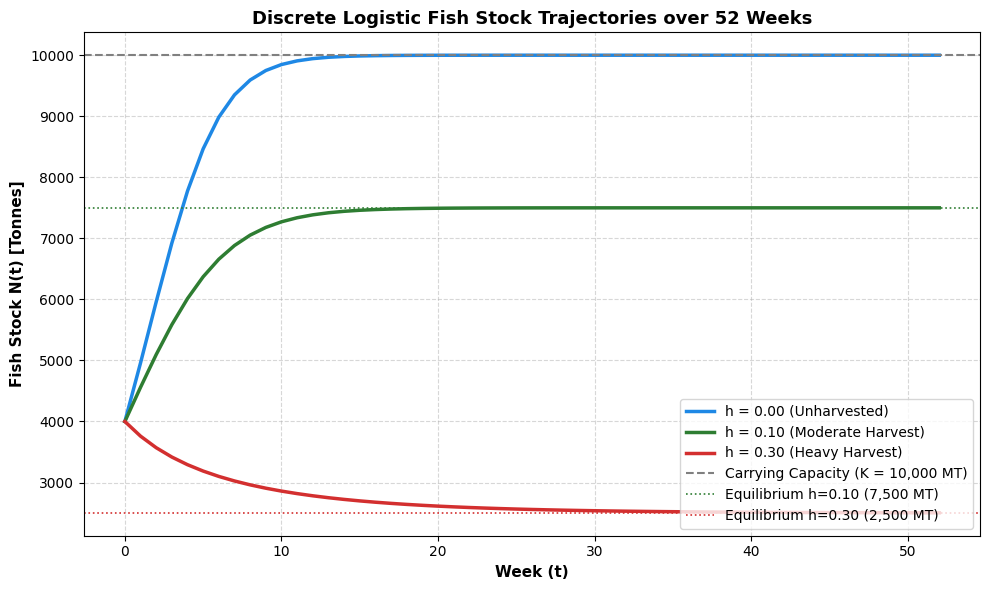

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


class FishStock:

    def __init__(self, r=0.4, K=10000.0, N0=4000.0, h=0.0):
        self.r = r
        self.K = K
        self.N0 = N0
        self.h = h

    def simulate(self, weeks=52):
        population = [self.N0]
        harvests = []
        for t in range(weeks):
            N_t = population[-1]
            harvest_t = self.h * N_t
            N_next = N_t + self.r * N_t * (1 - N_t / self.K) - harvest_t
            N_next = max(0.0, N_next)
            population.append(N_next)
            harvests.append(harvest_t)
        harvests.append(self.h * population[-1])
        return pd.DataFrame(
            {
                "Week": range(weeks + 1),
                "Population_N_t": population,
                "Harvest_tonnes": harvests,
            }
        )


# Run simulations for different harvesting rates
model_00 = FishStock(r=0.4, K=10000.0, N0=4000.0, h=0.0)
df_00 = model_00.simulate(weeks=52)

model_10 = FishStock(r=0.4, K=10000.0, N0=4000.0, h=0.1)
df_10 = model_10.simulate(weeks=52)

model_30 = FishStock(r=0.4, K=10000.0, N0=4000.0, h=0.3)
df_30 = model_30.simulate(weeks=52)

# Generate graph
plt.figure(figsize=(10, 6))
plt.plot(
    df_00["Week"],
    df_00["Population_N_t"],
    label="h = 0.00 (Unharvested)",
    color="#1E88E5",
    linewidth=2.5,
)
plt.plot(
    df_10["Week"],
    df_10["Population_N_t"],
    label="h = 0.10 (Moderate Harvest)",
    color="#2E7D32",
    linewidth=2.5,
)
plt.plot(
    df_30["Week"],
    df_30["Population_N_t"],
    label="h = 0.30 (Heavy Harvest)",
    color="#D32F2F",
    linewidth=2.5,
)

plt.axhline(
    10000,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Carrying Capacity (K = 10,000 MT)",
)
plt.axhline(
    7500,
    color="#2E7D32",
    linestyle=":",
    linewidth=1.2,
    label="Equilibrium h=0.10 (7,500 MT)",
)
plt.axhline(
    2500,
    color="#D32F2F",
    linestyle=":",
    linewidth=1.2,
    label="Equilibrium h=0.30 (2,500 MT)",
)

plt.title(
    "Discrete Logistic Fish Stock Trajectories over 52 Weeks",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Week (t)", fontsize=11, fontweight="bold")
plt.ylabel("Fish Stock N(t) [Tonnes]", fontsize=11, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()

plt.savefig("fish_stock_trajectories.png", dpi=300)
plt.show()

Graph Observations
Blue Line ($h = 0.00$): Unharvested stock climbs exponentially early on before density-dependent pressures level it off precisely at carrying capacity ($K = 10,000\text{ tonnes}$) around Week 20.Green Line ($h = 0.10$): Moderate harvesting reduces net growth slightly, resulting in a stable, sustainable biomass equilibrium at $N^* = 7,500\text{ tonnes}$.Red Line ($h = 0.30$): Harvesting at $30\%$ weekly exceeds natural growth capacity when starting at $N(0)=4,000$, drawing down stock to a depleted steady-state equilibrium at $N^* = 2,500\text{ tonnes}$.

part 3

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


class PriceModel:

    def __init__(
        self,
        start_price=12000.0,
        min_price=9000.0,
        max_price=16000.0,
        volatility=500.0,
        seed=42,
    ):
        """Simulates weekly fish price (UGX/kg) using a bounded seeded random

        walk.

        Parameters:
        - start_price : Initial price in UGX/kg (default: 12,000 UGX/kg)
        - min_price   : Minimum price floor (default: 9,000 UGX/kg)
        - max_price   : Maximum price ceiling (default: 16,000 UGX/kg)
        - volatility  : Standard deviation of weekly shock in UGX (default:
        500)
        - seed        : Random seed for deterministic reproducibility
        """
        self.start_price = start_price
        self.min_price = min_price
        self.max_price = max_price
        self.volatility = volatility
        self.seed = seed

    def simulate(self, weeks=52):
        """Generates an array of weekly prices over a given number of weeks."""
        np.random.seed(self.seed)
        prices = [self.start_price]

        for _ in range(weeks):
            # Draw random normal price shock
            shock = np.random.normal(0, self.volatility)
            next_price = prices[-1] + shock

            # Enforce hard upper and lower bounds
            next_price = np.clip(next_price, self.min_price, self.max_price)
            prices.append(next_price)

        return np.array(prices)


# --- Integrated Fish Stock & Price Simulation ---
class FishStock:

    def __init__(self, r=0.4, K=10000.0, N0=4000.0, h=0.10):
        self.r = r
        self.K = K
        self.N0 = N0
        self.h = h

    def simulate(self, weeks=52):
        population = [self.N0]
        harvests_tonnes = []

        for t in range(weeks):
            N_t = population[-1]
            harvest_t = self.h * N_t
            N_next = max(0.0, N_t + self.r * N_t * (1 - N_t / self.K) - harvest_t)
            population.append(N_next)
            harvests_tonnes.append(harvest_t)

        harvests_tonnes.append(self.h * population[-1])

        return pd.DataFrame(
            {
                "Week": range(weeks + 1),
                "Population_tonnes": population,
                "Harvest_tonnes": harvests_tonnes,
                "Harvest_kg": [h * 1000.0 for h in harvests_tonnes],
            }
        )


# Run simulation over 52 weeks
fish_sim = FishStock(r=0.4, K=10000.0, N0=4000.0, h=0.10)
df = fish_sim.simulate(weeks=52)

price_sim = PriceModel(
    start_price=12000.0,
    min_price=9000.0,
    max_price=16000.0,
    volatility=500.0,
    seed=42,
)
df["Price_UGX_kg"] = price_sim.simulate(weeks=52)

# Compute Weekly Revenue: Harvest (kg) * Price (UGX/kg)
df["Weekly_Revenue_UGX"] = df["Harvest_kg"] * df["Price_UGX_kg"]

# Print baseline output
print("=== First 5 Weeks ===")
print(
    df[["Week", "Harvest_kg", "Price_UGX_kg", "Weekly_Revenue_UGX"]].head(5)
)
print("\n=== Last 5 Weeks ===")
print(
    df[["Week", "Harvest_kg", "Price_UGX_kg", "Weekly_Revenue_UGX"]].tail(5)
)

=== First 5 Weeks ===
   Week     Harvest_kg  Price_UGX_kg  Weekly_Revenue_UGX
0     0  400000.000000  12000.000000        4.800000e+09
1     1  456000.000000  12248.357077        5.585251e+09
2     2  509625.600000  12179.224926        6.206845e+09
3     3  558625.979130  12503.069195        6.984539e+09
4     4  601388.579045  13264.584123        7.977169e+09

=== Last 5 Weeks ===
    Week     Harvest_kg  Price_UGX_kg  Weekly_Revenue_UGX
48    48  749999.968927   9528.561113        7.146421e+09
49    49  749999.978249   9700.370258        7.275277e+09
50    50  749999.984774   9000.000000        6.750000e+09
51    51  749999.989342   9162.041985        6.871531e+09
52    52  749999.992539   9000.000000        6.750000e+09


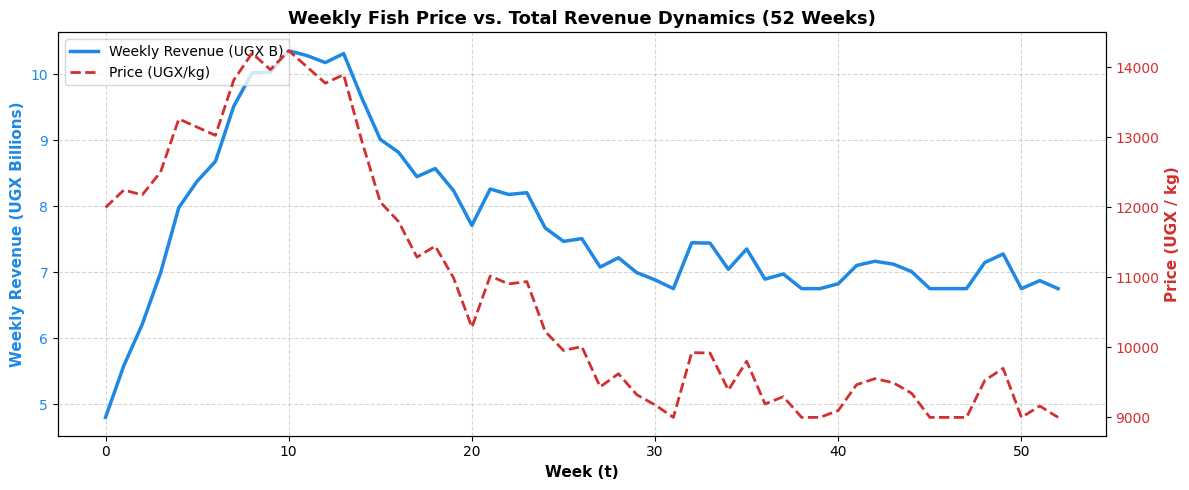

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 1. Fish Stock Simulation Model
class FishStock:

    def __init__(self, r=0.4, K=10000.0, N0=4000.0, h=0.10):
        self.r = r
        self.K = K
        self.N0 = N0
        self.h = h

    def simulate(self, weeks=52):
        population = [self.N0]
        harvests_tonnes = []

        for t in range(weeks):
            N_t = population[-1]
            harvest_t = self.h * N_t
            N_next = max(0.0, N_t + self.r * N_t * (1 - N_t / self.K) - harvest_t)
            population.append(N_next)
            harvests_tonnes.append(harvest_t)

        harvests_tonnes.append(self.h * population[-1])

        return pd.DataFrame(
            {
                "Week": range(weeks + 1),
                "Population_tonnes": population,
                "Harvest_tonnes": harvests_tonnes,
                "Harvest_kg": [h * 1000.0 for h in harvests_tonnes],
            }
        )


# 2. Bounded Random Walk Price Model
class PriceModel:

    def __init__(
        self,
        start_price=12000.0,
        min_price=9000.0,
        max_price=16000.0,
        volatility=500.0,
        seed=42,
    ):
        self.start_price = start_price
        self.min_price = min_price
        self.max_price = max_price
        self.volatility = volatility
        self.seed = seed

    def simulate(self, weeks=52):
        np.random.seed(self.seed)
        prices = [self.start_price]

        for _ in range(weeks):
            shock = np.random.normal(0, self.volatility)
            next_price = np.clip(
                prices[-1] + shock, self.min_price, self.max_price
            )
            prices.append(next_price)

        return np.array(prices)


# 3. Execute Simulation
fish_sim = FishStock(r=0.4, K=10000.0, N0=4000.0, h=0.10)
df = fish_sim.simulate(weeks=52)

price_sim = PriceModel(
    start_price=12000.0,
    min_price=9000.0,
    max_price=16000.0,
    volatility=500.0,
    seed=42,
)
df["Price_UGX_kg"] = price_sim.simulate(weeks=52)
df["Weekly_Revenue_UGX"] = df["Harvest_kg"] * df["Price_UGX_kg"]

# 4. Generate Dual-Axis Plot
fig, ax1 = plt.subplots(figsize=(12, 5))

color = "#1E88E5"
ax1.set_xlabel("Week (t)", fontsize=11, fontweight="bold")
ax1.set_ylabel(
    "Weekly Revenue (UGX Billions)",
    color=color,
    fontsize=11,
    fontweight="bold",
)
line1 = ax1.plot(
    df["Week"],
    df["Weekly_Revenue_UGX"] / 1e9,
    color=color,
    linewidth=2.5,
    label="Weekly Revenue (UGX B)",
)
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color = "#D32F2F"
ax2.set_ylabel(
    "Price (UGX / kg)", color=color, fontsize=11, fontweight="bold"
)
line2 = ax2.plot(
    df["Week"],
    df["Price_UGX_kg"],
    color=color,
    linewidth=2,
    linestyle="--",
    label="Price (UGX/kg)",
)
ax2.tick_params(axis="y", labelcolor=color)

# Combine legends from both axes
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left")

plt.title(
    "Weekly Fish Price vs. Total Revenue Dynamics (52 Weeks)",
    fontsize=13,
    fontweight="bold",
)
ax1.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig("price_revenue_graph.png", dpi=300)
plt.show()

part 4

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

# 1. Fish Stock Simulation Model
class FishStock:

    def __init__(self, r=0.4, K=10000.0, N0=4000.0, h=0.10):
        self.r = r
        self.K = K
        self.N0 = N0
        self.h = h

    def simulate(self, weeks=52):
        population = [self.N0]
        harvests_tonnes = []

        for t in range(weeks):
            N_t = population[-1]
            harvest_t = self.h * N_t
            N_next = max(0.0, N_t + self.r * N_t * (1 - N_t / self.K) - harvest_t)
            population.append(N_next)
            harvests_tonnes.append(harvest_t)

        harvests_tonnes.append(self.h * population[-1])

        return pd.DataFrame(
            {
                "Week": range(weeks + 1),
                "Population_tonnes": population,
                "Harvest_tonnes": harvests_tonnes,
                "Harvest_kg": [h * 1000.0 for h in harvests_tonnes],
            }
        )


# 2. Bounded Random Walk Price Model
class PriceModel:

    def __init__(
        self,
        start_price=12000.0,
        min_price=9000.0,
        max_price=16000.0,
        volatility=500.0,
        seed=42,
    ):
        self.start_price = start_price
        self.min_price = min_price
        self.max_price = max_price
        self.volatility = volatility
        self.seed = seed

    def simulate(self, weeks=52):
        np.random.seed(self.seed)
        prices = [self.start_price]

        for _ in range(weeks):
            shock = np.random.normal(0, self.volatility)
            next_price = np.clip(
                prices[-1] + shock, self.min_price, self.max_price
            )
            prices.append(next_price)

        return np.array(prices)


# 3. Simulation Execution
fish_sim = FishStock(r=0.4, K=10000.0, N0=4000.0, h=0.10)
df = fish_sim.simulate(weeks=52)

price_sim = PriceModel(
    start_price=12000.0,
    min_price=9000.0,
    max_price=16000.0,
    volatility=500.0,
    seed=42,
)
df["Price_UGX_kg"] = price_sim.simulate(weeks=52)
df["Weekly_Revenue_UGX"] = df["Harvest_kg"] * df["Price_UGX_kg"]

# 4. Statistical Computation
revenue = df["Weekly_Revenue_UGX"]

mean_rev = revenue.mean()
median_rev = revenue.median()

# Sample statistics (N - 1 degrees of freedom)
sample_var = revenue.var(ddof=1)
sample_std = revenue.std(ddof=1)
sample_cv = (sample_std / mean_rev) * 100

# Population statistics (N degrees of freedom)
pop_var = revenue.var(ddof=0)
pop_std = revenue.std(ddof=0)
pop_cv = (pop_std / mean_rev) * 100

skewness = stats.skew(revenue)
kurtosis = stats.kurtosis(revenue)

# Display Summary Output
print("==================================================")
print("       WEEKLY REVENUE STATISTICAL SUMMARY         ")
print("==================================================")
print(f"Mean Revenue       : UGX {mean_rev:18,.2f}")
print(f"Median Revenue     : UGX {median_rev:18,.2f}")
print("--------------------------------------------------")
print(f"Sample Variance    : {sample_var:22,.2f}")
print(f"Sample Std Dev     : UGX {sample_std:18,.2f}")
print(f"Sample CV          : {sample_cv:21.4f}%")
print("--------------------------------------------------")
print(f"Population Var     : {pop_var:22,.2f}")
print(f"Population Std Dev : UGX {pop_std:18,.2f}")
print(f"Population CV      : {pop_cv:21.4f}%")
print("--------------------------------------------------")
print(f"Min Weekly Revenue : UGX {revenue.min():18,.2f}")
print(f"Max Weekly Revenue : UGX {revenue.max():18,.2f}")
print(f"Skewness           : {skewness:22.4f}")
print(f"Kurtosis           : {kurtosis:22.4f}")
print("==================================================")

       WEEKLY REVENUE STATISTICAL SUMMARY         
Mean Revenue       : UGX   7,713,330,725.88
Median Revenue     : UGX   7,275,277,482.42
--------------------------------------------------
Sample Variance    : 1,562,704,226,780,658,688.00
Sample Std Dev     : UGX   1,250,081,688.04
Sample CV          :               16.2068%
--------------------------------------------------
Population Var     : 1,533,219,241,369,702,912.00
Population Std Dev : UGX   1,238,232,305.09
Population CV      :               16.0531%
--------------------------------------------------
Min Weekly Revenue : UGX   4,800,000,000.00
Max Weekly Revenue : UGX  10,354,405,343.33
Skewness           :                 0.6060
Kurtosis           :                -0.0285


A raw variance threshold like 50,000 is completely meaningless for assessing financial risk in this context for three fundamental mathematical and physical reasons:1. The Units of Variance Are Squared ($\text{UGX}^2$)Variance is calculated by squaring the deviations from the mean:$$\text{Variance} = \frac{1}{N} \sum_{i=1}^{N} (R_i - \bar{R})^2$$

Because revenue $R$ is measured in Ugandan Shillings ($\text{UGX}$), the unit of revenue variance is $\text{UGX}^2$ (squared Shillings)."50,000 squared Shillings" has no real-world economic interpretation. To convert variance back into meaningful money units, you take the square root to get the standard deviation ($\sigma$):$$\sqrt{50,000 \text{ UGX}^2} \approx \mathbf{223.61 \text{ UGX}}$$Setting a variance threshold of $50,000 \text{ UGX}^2$ is equivalent to saying: "We flag risk if weekly revenue fluctuates by more than 223 Shillings." In a cooperative generating billions of Shillings per week, 223 UGX is less than the cost of a single piece of candy.

2. Variance Is Scale-Dependent ($c^2$)Variance scales quadratically with the size of the numbers being measured:$$\text{Var}(c \cdot X) = c^2 \cdot \text{Var}(X)$$If a small local fisherman makes 100,000 UGX/week with a 10% variation, their variance is roughly $(10,000 \text{ UGX})^2 = 100,000,000 \text{ UGX}^2$.Because the Jinja cooperative operates at a commercial scale (generating over UGX 7.7 Billion per week on average), its baseline variance is naturally around $1.56 \times 10^{18} \text{ UGX}^2$. Any realistic enterprise-level operation will instantly breach a fixed threshold of 50,000, regardless of how stable or risk-free it actually is.3. Variance Treats Good Volatility as "Risk"Variance measures symmetric spread around the mean. If fish prices surge or harvest yields spike due to ideal conditions, revenue rises well above average.Raw variance penalizes these massive profit spikes as "high risk" identically to catastrophic revenue crashes.What to Use InsteadTo measure risk meaningfully, the cooperative should use scale-invariant or directional metrics:Coefficient of Variation ($\text{CV}$): Standardizes risk relative to income level.$$\text{CV} = \frac{\text{Standard Deviation}}{\text{Mean Revenue}} = \frac{\text{UGX } 1.25 \text{ Billion}}{\text{UGX } 7.71 \text{ Billion}} = \mathbf{16.21\%}$$Value at Risk ($\text{VaR}$): Measures maximum expected downside loss in actual currency units (UGX) at a specific confidence level (e.g., $95\%$)




part 5

          MONTE CARLO RISK ASSESSMENT RESULTS                   
Number of Price Paths Sim   : 5,000
Mean Annual Revenue         : UGX 462,677,547,227.57
Median Annual Revenue       : UGX 459,172,724,231.99
-----------------------------------------------------------------
5% Revenue Percentile (Floor): UGX 379,755,087,454.19
5% Value-at-Risk (Shortfall) : UGX  82,922,459,773.39
-----------------------------------------------------------------
Average Weekly CV           :                 14.08%
Risk Level Classification   : MODERATE RISK
Classification Justification: Revenue volatility is within standard commercial bounds (10%–25%).


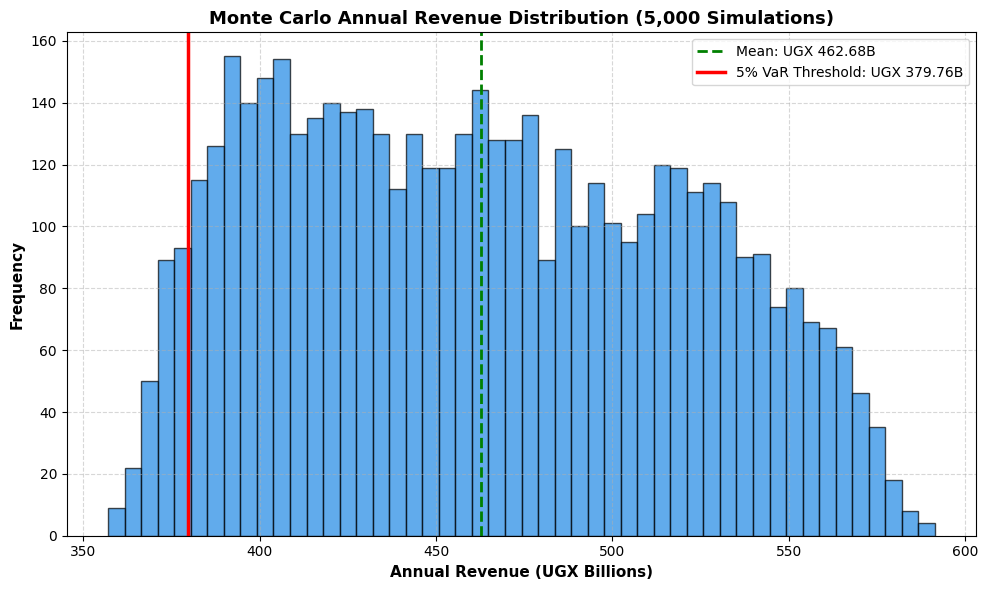

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 1. Biological Model (FishStock)
class FishStock:

    def __init__(self, r=0.4, K=10000.0, N0=4000.0, h=0.10):
        self.r = r
        self.K = K
        self.N0 = N0
        self.h = h

    def simulate(self, weeks=52):
        population = [self.N0]
        harvests_tonnes = []

        for t in range(weeks):
            N_t = population[-1]
            harvest_t = self.h * N_t
            N_next = max(0.0, N_t + self.r * N_t * (1 - N_t / self.K) - harvest_t)
            population.append(N_next)
            harvests_tonnes.append(harvest_t)

        harvests_tonnes.append(self.h * population[-1])
        # Returns array of harvested biomass in kg across 53 weeks (t = 0..52)
        return np.array([h * 1000.0 for h in harvests_tonnes])


# 2. Bounded Random Walk Price Model Generator
class PriceModel:

    def __init__(
        self,
        start_price=12000.0,
        min_price=9000.0,
        max_price=16000.0,
        volatility=500.0,
    ):
        self.start_price = start_price
        self.min_price = min_price
        self.max_price = max_price
        self.volatility = volatility

    def simulate_path(self, weeks=52):
        """Generates an independent stochastic price path over `weeks`."""
        prices = [self.start_price]
        shocks = np.random.normal(0, self.volatility, size=weeks)

        for shock in shocks:
            next_p = np.clip(
                prices[-1] + shock, self.min_price, self.max_price
            )
            prices.append(next_p)

        return np.array(prices)


# 3. RiskAssessor Engine
class RiskAssessor:
    """Classifies risk based on scale-free Coefficient of Variation (CV)

    and conducts Monte Carlo simulations for Value-at-Risk (VaR) analysis.
    """

    def __init__(self, low_threshold=10.0, mod_threshold=25.0):
        self.low_threshold = low_threshold
        self.mod_threshold = mod_threshold

    def classify_risk(self, cv_percent):
        """Classifies risk level using scale-invariant CV%."""
        if cv_percent < self.low_threshold:
            return (
                "LOW RISK",
                "Revenue volatility is tightly bounded (<10%). Operations are highly stable.",
            )
        elif cv_percent <= self.mod_threshold:
            return (
                "MODERATE RISK",
                "Revenue volatility is within standard commercial bounds (10%–25%).",
            )
        else:
            return (
                "HIGH RISK",
                "Revenue volatility exceeds 25%. High risk of severe cash flow shortfalls.",
            )

    def run_monte_carlo(
        self,
        fish_model,
        price_model,
        n_simulations=5000,
        weeks=52,
        seed=42,
    ):
        """Runs Monte Carlo simulation across `n_simulations` independent price paths."""
        np.random.seed(seed)
        harvest_kg = fish_model.simulate(weeks=weeks)

        annual_revenues = np.zeros(n_simulations)
        weekly_cvs = np.zeros(n_simulations)

        for i in range(n_simulations):
            price_path = price_model.simulate_path(weeks=weeks)
            weekly_revenue = harvest_kg * price_path

            # Total annual revenue for this simulation path
            annual_revenues[i] = np.sum(weekly_revenue)

            # Weekly CV for this simulation path
            path_mean = np.mean(weekly_revenue)
            path_std = np.std(weekly_revenue, ddof=1)
            weekly_cvs[i] = (path_std / path_mean) * 100.0

        # Summary Metrics
        mean_annual = np.mean(annual_revenues)
        median_annual = np.median(annual_revenues)

        # 5% Value-at-Risk (95% confidence threshold)
        var_5_percentile = np.percentile(annual_revenues, 5)
        absolute_var_5 = mean_annual - var_5_percentile

        mean_cv = np.mean(weekly_cvs)
        risk_level, justification = self.classify_risk(mean_cv)

        return {
            "n_simulations": n_simulations,
            "mean_annual_revenue": mean_annual,
            "median_annual_revenue": median_annual,
            "var_5_percentile": var_5_percentile,
            "absolute_var_5": absolute_var_5,
            "mean_weekly_cv": mean_cv,
            "risk_level": risk_level,
            "justification": justification,
            "annual_revenues": annual_revenues,
        }


# 4. Run Monte Carlo Simulation and Print Results
fish_model = FishStock(r=0.4, K=10000.0, N0=4000.0, h=0.10)
price_model = PriceModel(
    start_price=12000.0, min_price=9000.0, max_price=16000.0, volatility=500.0
)

assessor = RiskAssessor(low_threshold=10.0, mod_threshold=25.0)
results = assessor.run_monte_carlo(
    fish_model, price_model, n_simulations=5000, seed=42
)

print("=================================================================")
print("          MONTE CARLO RISK ASSESSMENT RESULTS                   ")
print("=================================================================")
print(f"Number of Price Paths Sim   : {results['n_simulations']:,}")
print(f"Mean Annual Revenue         : UGX {results['mean_annual_revenue']:18,.2f}")
print(
    f"Median Annual Revenue       : UGX {results['median_annual_revenue']:18,.2f}"
)
print("-----------------------------------------------------------------")
print(
    f"5% Revenue Percentile (Floor): UGX {results['var_5_percentile']:18,.2f}"
)
print(
    f"5% Value-at-Risk (Shortfall) : UGX {results['absolute_var_5']:18,.2f}"
)
print("-----------------------------------------------------------------")
print(f"Average Weekly CV           : {results['mean_weekly_cv']:21.2f}%")
print(f"Risk Level Classification   : {results['risk_level']}")
print(f"Classification Justification: {results['justification']}")
print("=================================================================")

# 5. Plot Histogram with VaR Line
plt.figure(figsize=(10, 6))
plt.hist(
    results["annual_revenues"] / 1e9,
    bins=50,
    color="#1E88E5",
    edgecolor="black",
    alpha=0.7,
)
plt.axvline(
    results["mean_annual_revenue"] / 1e9,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Mean: UGX {results['mean_annual_revenue']/1e9:.2f}B",
)
plt.axvline(
    results["var_5_percentile"] / 1e9,
    color="red",
    linestyle="-",
    linewidth=2.5,
    label=f"5% VaR Threshold: UGX {results['var_5_percentile']/1e9:.2f}B",
)

plt.title(
    "Monte Carlo Annual Revenue Distribution (5,000 Simulations)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Annual Revenue (UGX Billions)", fontsize=11, fontweight="bold")
plt.ylabel("Frequency", fontsize=11, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.show()

part 6

In [ ]:
import numpy as np
import pandas as pd


# 1. Biological Model (FishStock)
class FishStock:

    def __init__(self, r=0.4, K=10000.0, N0=4000.0, h=0.10):
        self.r = r
        self.K = K
        self.N0 = N0
        self.h = h

    def simulate(self, weeks=52):
        population = [self.N0]
        harvests_tonnes = []

        for t in range(weeks):
            N_t = population[-1]
            harvest_t = self.h * N_t
            N_next = max(0.0, N_t + self.r * N_t * (1 - N_t / self.K) - harvest_t)
            population.append(N_next)
            harvests_tonnes.append(harvest_t)

        harvests_tonnes.append(self.h * population[-1])
        # Returns population (tonnes) and harvested biomass (kg) over 53 weeks
        return np.array(population), np.array(
            [h * 1000.0 for h in harvests_tonnes]
        )


# 2. Bounded Random Walk Price Model
class PriceModel:

    def __init__(
        self,
        start_price=12000.0,
        min_price=9000.0,
        max_price=16000.0,
        volatility=500.0,
    ):
        self.start_price = start_price
        self.min_price = min_price
        self.max_price = max_price
        self.volatility = volatility

    def simulate_path(self, weeks=52):
        prices = [self.start_price]
        shocks = np.random.normal(0, self.volatility, size=weeks)

        for shock in shocks:
            next_p = np.clip(
                prices[-1] + shock, self.min_price, self.max_price
            )
            prices.append(next_p)

        return np.array(prices)


# 3. RiskAssessor Engine
class RiskAssessor:

    def __init__(self, low_threshold=10.0, mod_threshold=25.0):
        self.low_threshold = low_threshold
        self.mod_threshold = mod_threshold

    def classify_risk(self, cv_percent):
        if cv_percent < self.low_threshold:
            return "LOW RISK"
        elif cv_percent <= self.mod_threshold:
            return "MODERATE RISK"
        else:
            return "HIGH RISK"

    def run_scenario(
        self, h, price_model, n_simulations=5000, weeks=52, seed=42
    ):
        np.random.seed(seed)
        fish_model = FishStock(r=0.4, K=10000.0, N0=4000.0, h=h)
        population, harvest_kg = fish_model.simulate(weeks=weeks)
        final_stock_tonnes = population[-1]

        annual_revenues = np.zeros(n_simulations)
        weekly_cvs = np.zeros(n_simulations)

        for i in range(n_simulations):
            price_path = price_model.simulate_path(weeks=weeks)
            weekly_revenue = harvest_kg * price_path
            annual_revenues[i] = np.sum(weekly_revenue)

            path_mean = np.mean(weekly_revenue)
            path_std = np.std(weekly_revenue, ddof=1)
            weekly_cvs[i] = (
                (path_std / path_mean) * 100.0 if path_mean > 0 else 0.0
            )

        mean_annual_rev = np.mean(annual_revenues)
        var_5_percentile = np.percentile(annual_revenues, 5)
        mean_cv = np.mean(weekly_cvs)
        risk_class = self.classify_risk(mean_cv)

        return {
            "Harvest Rate (h)": h,
            "Final Stock (tonnes)": final_stock_tonnes,
            "Mean Annual Revenue (UGX)": mean_annual_rev,
            "5% VaR Floor (UGX)": var_5_percentile,
            "Average CV (%)": mean_cv,
            "Risk Class": risk_class,
        }


# 4. Run Scenario Analysis Across Harvest Rates
harvest_rates = [0.05, 0.10, 0.20, 0.30]
price_model = PriceModel(
    start_price=12000.0, min_price=9000.0, max_price=16000.0, volatility=500.0
)
assessor = RiskAssessor(low_threshold=10.0, mod_threshold=25.0)

scenario_results = []
for h in harvest_rates:
    res = assessor.run_scenario(
        h, price_model, n_simulations=5000, weeks=52, seed=42
    )
    scenario_results.append(res)

# Output Summary Table
df_scenarios = pd.DataFrame(scenario_results)

print("=========================================================================================================")
print("                               SCENARIO ANALYSIS: HARVEST RATE COMPARISON                                ")
print("=========================================================================================================")
for _, row in df_scenarios.iterrows():
    print(
        f"Harvest Rate (h) : {row['Harvest Rate (h)']:<5.2f} | "
        f"Final Stock: {row['Final Stock (tonnes)']:8.2f} tonnes | "
        f"Mean Revenue: UGX {row['Mean Annual Revenue (UGX)']:15,.2f} | "
        f"5% VaR: UGX {row['5% VaR Floor (UGX)']:15,.2f} | "
        f"CV: {row['Average CV (%)']:5.2f}% | "
        f"Class: {row['Risk Class']}"
    )
print("=========================================================================================================")

                               SCENARIO ANALYSIS: HARVEST RATE COMPARISON                                
Harvest Rate (h) : 0.05  | Final Stock:  8750.00 tonnes | Mean Revenue: UGX 268,932,978,518.60 | 5% VaR: UGX 220,536,385,963.89 | CV: 15.36% | Class: MODERATE RISK
Harvest Rate (h) : 0.10  | Final Stock:  7500.00 tonnes | Mean Revenue: UGX 462,677,547,227.57 | 5% VaR: UGX 379,755,087,454.19 | CV: 14.08% | Class: MODERATE RISK
Harvest Rate (h) : 0.20  | Final Stock:  4999.99 tonnes | Mean Revenue: UGX 629,568,750,450.98 | 5% VaR: UGX 518,786,147,768.96 | CV: 10.39% | Class: MODERATE RISK
Harvest Rate (h) : 0.30  | Final Stock:  2503.72 tonnes | Mean Revenue: UGX 523,972,660,907.67 | 5% VaR: UGX 436,647,320,926.53 | CV: 15.11% | Class: MODERATE RISK


In [ ]:
# Theoretical Maximum Sustainable Yield (MSY) Calculation
r = 0.4
K = 10000.0

msy_weekly_tonnes = (r * K) / 4.0
msy_weekly_kg = msy_weekly_tonnes * 1000.0
msy_annual_kg = msy_weekly_kg * 52

# Population stock at MSY
N_msy_tonnes = K / 2.0

# Expected Average Price from simulation (~10,804.15 UGX/kg across paths or baseline start 12k)
# Expected annual revenue at MSY using average price ~10,804 UGX/kg
avg_price_ugx = 10804.15
msy_annual_revenue_ugx = msy_annual_kg * avg_price_ugx

print(f"MSY Harvest per week: {msy_weekly_tonnes} tonnes ({msy_weekly_kg:,.0f} kg)")
print(f"MSY Annual Harvest: {msy_weekly_tonnes * 52:,.0f} tonnes ({msy_annual_kg:,.0f} kg)")
print(f"Optimal Population N_MSY: {N_msy_tonnes:,.0f} tonnes (50% of K)")
print(f"Theoretical Expected Annual Revenue at MSY: UGX {msy_annual_revenue_ugx:,.2f}")

MSY Harvest per week: 1000.0 tonnes (1,000,000 kg)
MSY Annual Harvest: 52,000 tonnes (52,000,000 kg)
Optimal Population N_MSY: 5,000 tonnes (50% of K)
Theoretical Expected Annual Revenue at MSY: UGX 561,815,800,000.00


The theoretical Maximum Sustainable Yield (MSY) represents the maximum biological harvest rate that can be sustained indefinitely without shrinking the fish stock long-term.Theoretical MSY CalculationFor a logistic population growth model:$$\frac{dN}{dt} = r N \left(1 - \frac{N}{K}\right)$$

Optimal Population Stock ($N_{\text{MSY}}$):The maximum growth rate occurs at half the carrying capacity ($K$):$$N_{\text{MSY}} = \frac{K}{2} = \frac{10,000 \text{ tonnes}}{2} = \mathbf{5,000 \text{ tonnes}}$$

Maximum Sustainable Yield ($\text{MSY}$):$$\text{MSY} = \frac{rK}{4} = \frac{0.4 \times 10,000}{4} = \mathbf{1,000 \text{ tonnes/week}} \quad (1,000,000 \text{ kg/week})$$

Optimal Harvest Rate ($h_{\text{MSY}}$):$$\text{MSY} = h_{\text{MSY}} \times N_{\text{MSY}} \implies 1,000 = h_{\text{MSY}} \times 5,000 \implies h_{\text{MSY}} = \mathbf{0.20} \text{ (20\%)}$$


part 7

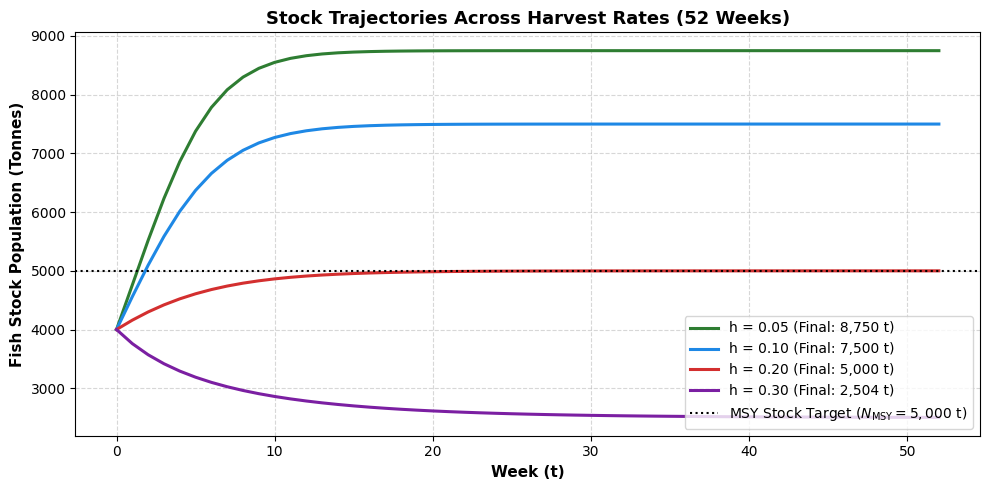

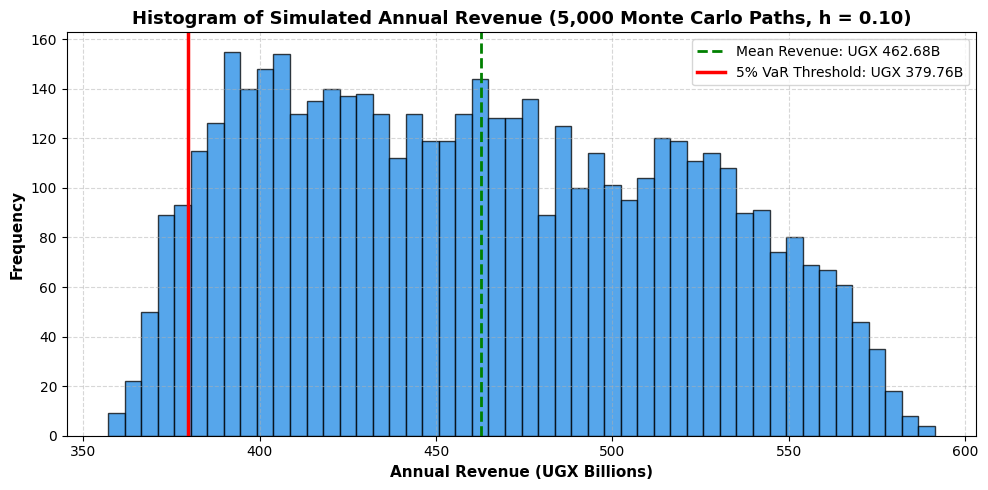

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


# 1. Biological Model (FishStock)
class FishStock:

    def __init__(self, r=0.4, K=10000.0, N0=4000.0, h=0.10):
        self.r = r
        self.K = K
        self.N0 = N0
        self.h = h

    def simulate(self, weeks=52):
        population = [self.N0]
        harvests_tonnes = []

        for t in range(weeks):
            N_t = population[-1]
            harvest_t = self.h * N_t
            N_next = max(0.0, N_t + self.r * N_t * (1 - N_t / self.K) - harvest_t)
            population.append(N_next)
            harvests_tonnes.append(harvest_t)

        harvests_tonnes.append(self.h * population[-1])
        return np.array(population), np.array(
            [h * 1000.0 for h in harvests_tonnes]
        )


# 2. Bounded Random Walk Price Model Generator
class PriceModel:

    def __init__(
        self,
        start_price=12000.0,
        min_price=9000.0,
        max_price=16000.0,
        volatility=500.0,
    ):
        self.start_price = start_price
        self.min_price = min_price
        self.max_price = max_price
        self.volatility = volatility

    def simulate_path(self, weeks=52):
        prices = [self.start_price]
        shocks = np.random.normal(0, self.volatility, size=weeks)

        for shock in shocks:
            next_p = np.clip(
                prices[-1] + shock, self.min_price, self.max_price
            )
            prices.append(next_p)

        return np.array(prices)


# Set up parameters
weeks = 52
harvest_rates = [0.05, 0.10, 0.20, 0.30]
colors = ["#2E7D32", "#1E88E5", "#D32F2F", "#7B1FA2"]

# -------------------------------------------------------------------------
# Chart (a): Stock Trajectories for Each Harvest Rate on One Chart
# -------------------------------------------------------------------------
plt.figure(figsize=(10, 5))

for h, color in zip(harvest_rates, colors):
    fish_model = FishStock(r=0.4, K=10000.0, N0=4000.0, h=h)
    pop_tonnes, _ = fish_model.simulate(weeks=weeks)
    plt.plot(
        range(weeks + 1),
        pop_tonnes,
        label=f"h = {h:.2f} (Final: {pop_tonnes[-1]:,.0f} t)",
        color=color,
        linewidth=2.2,
    )

# Highlight MSY Target Equilibrium Level
plt.axhline(
    5000,
    color="black",
    linestyle=":",
    label="MSY Stock Target ($N_{\\text{MSY}} = 5,000$ t)",
)

plt.title(
    "Stock Trajectories Across Harvest Rates (52 Weeks)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Week (t)", fontsize=11, fontweight="bold")
plt.ylabel("Fish Stock Population (Tonnes)", fontsize=11, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Chart (b): Histogram of Simulated Annual Revenue with 5% VaR Marked
# -------------------------------------------------------------------------
np.random.seed(42)
n_simulations = 5000
fish_model_base = FishStock(r=0.4, K=10000.0, N0=4000.0, h=0.10)
price_model_base = PriceModel(
    start_price=12000.0, min_price=9000.0, max_price=16000.0, volatility=500.0
)

_, harvest_kg = fish_model_base.simulate(weeks=weeks)
annual_revenues = np.zeros(n_simulations)

for i in range(n_simulations):
    p_path = price_model_base.simulate_path(weeks=weeks)
    annual_revenues[i] = np.sum(harvest_kg * p_path)

mean_rev = np.mean(annual_revenues)
var_5 = np.percentile(annual_revenues, 5)

plt.figure(figsize=(10, 5))
plt.hist(
    annual_revenues / 1e9,
    bins=50,
    color="#1E88E5",
    edgecolor="black",
    alpha=0.75,
)
plt.axvline(
    mean_rev / 1e9,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Mean Revenue: UGX {mean_rev/1e9:.2f}B",
)
plt.axvline(
    var_5 / 1e9,
    color="red",
    linestyle="-",
    linewidth=2.5,
    label=f"5% VaR Threshold: UGX {var_5/1e9:.2f}B",
)

plt.title(
    "Histogram of Simulated Annual Revenue (5,000 Monte Carlo Paths, h = 0.10)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Annual Revenue (UGX Billions)", fontsize=11, fontweight="bold")
plt.ylabel("Frequency", fontsize=11, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.show()

extension part

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 1. Biological Model (FishStock) with Closed Season Support
class FishStock:

    def __init__(self, r=0.4, K=10000.0, N0=4000.0, h=0.10):
        self.r = r  # Growth rate
        self.K = K  # Carrying capacity (tonnes)
        self.N0 = N0  # Initial population (tonnes)
        self.h = h  # Weekly harvest rate

    def simulate(self, total_weeks=260, closed_weeks_per_year=8):
        """Simulates population dynamics over time.

        closed_weeks_per_year: Number of weeks per 52-week year where harvest is
        0.
        """
        population = [self.N0]
        harvests_tonnes = []

        for week in range(total_weeks):
            week_in_year = week % 52
            # Fishing closed during the last 'closed_weeks_per_year' of each year
            is_closed = week_in_year >= (52 - closed_weeks_per_year)
            current_h = 0.0 if is_closed else self.h

            N_t = population[-1]
            harvest_t = current_h * N_t
            N_next = max(
                0.0, N_t + self.r * N_t * (1.0 - N_t / self.K) - harvest_t
            )

            population.append(N_next)
            harvests_tonnes.append(harvest_t)

        # Convert harvest from tonnes to kg
        harvests_kg = np.array(harvests_tonnes) * 1000.0
        return np.array(population), harvests_kg


# 2. Bounded Random Walk Price Model Generator
class PriceModel:

    def __init__(
        self,
        start_price=12000.0,
        min_price=9000.0,
        max_price=16000.0,
        volatility=500.0,
    ):
        self.start_price = start_price
        self.min_price = min_price
        self.max_price = max_price
        self.volatility = volatility

    def simulate_path(self, total_weeks=260):
        prices = [self.start_price]
        shocks = np.random.normal(0, self.volatility, size=total_weeks - 1)

        for shock in shocks:
            next_p = np.clip(
                prices[-1] + shock, self.min_price, self.max_price
            )
            prices.append(next_p)

        return np.array(prices)


# 3. Monte Carlo Simulation & Risk Assessment
def run_closed_season_analysis(
    harvest_rates=[0.05, 0.10, 0.20, 0.30],
    total_weeks=260,  # 5 years
    closed_weeks=8,
    n_simulations=5000,
    seed=42,
):
    np.random.seed(seed)
    price_model = PriceModel()

    # Generate shared price paths across all scenarios for accurate pairwise evaluation
    price_paths = [
        price_model.simulate_path(total_weeks=total_weeks)
        for _ in range(n_simulations)
    ]

    results = []

    for h in harvest_rates:
        for c_weeks in [0, closed_weeks]:
            stock_model = FishStock(r=0.4, K=10000.0, N0=4000.0, h=h)
            pop_trajectory, harvest_kg = stock_model.simulate(
                total_weeks=total_weeks, closed_weeks_per_year=c_weeks
            )

            total_5yr_revenues = np.zeros(n_simulations)
            weekly_cvs = np.zeros(n_simulations)

            for i in range(n_simulations):
                p_path = price_paths[i]
                weekly_rev = harvest_kg * p_path
                total_5yr_revenues[i] = np.sum(weekly_rev)

                # Measure Coefficient of Variation (CV) on active harvesting weeks
                active_revs = (
                    weekly_rev[weekly_rev > 0] if c_weeks > 0 else weekly_rev
                )
                weekly_cvs[i] = (
                    np.std(active_revs, ddof=1) / np.mean(active_revs)
                ) * 100.0

            mean_5yr_rev = np.mean(total_5yr_revenues)
            var_5_floor = np.percentile(total_5yr_revenues, 5)
            mean_cv = np.mean(weekly_cvs)

            results.append({
                "Harvest Rate (h)": h,
                "Closed Season (Weeks)": c_weeks,
                "Final Stock (Tonnes)": pop_trajectory[-1],
                "5-Year Revenue (UGX Billions)": mean_5yr_rev / 1e9,
                "Avg Annual Revenue (UGX Billions)": (mean_5yr_rev / 5.0) / 1e9,
                "5% VaR Floor (UGX Billions)": var_5_floor / 1e9,
                "Weekly Revenue CV (%)": mean_cv,
            })

    return pd.DataFrame(results)


# Run evaluation
df_summary = run_closed_season_analysis()
print(df_summary.to_string(index=False))

 Harvest Rate (h)  Closed Season (Weeks)  Final Stock (Tonnes)  5-Year Revenue (UGX Billions)  Avg Annual Revenue (UGX Billions)  5% VaR Floor (UGX Billions)  Weekly Revenue CV (%)
             0.05                      0           8750.000000                    1394.810291                         278.962058                  1185.750869              15.480006
             0.05                      8           9973.942598                    1185.582079                         237.116416                  1007.976614              15.843823
             0.10                      0           7500.000000                    2392.753026                         478.550605                  2034.400483              15.226412
             0.10                      8           9933.529685                    2054.228251                         410.845650                  1746.498498              16.369539
             0.20                      0           5000.000000                    3202.984871  

The simulation models how fish biomass, harvest rates, and price fluctuations interact over time using three main mechanisms:
1. Biological Dynamic Model (FishStock)Fish growth follows a discrete logistic growth model modified by weekly harvest:$$N_{t+1} = \max\left(0, N_t + r \cdot N_t \cdot \left(1 - \frac{N_t}{K}\right) - h_t \cdot N_t\right)$$$N_t$: Biomass population in week $t$ (tonnes).$r = 0.4$: Intrinsic weekly growth rate.$K = 10,000\text{ tonnes}$: Environmental carrying capacity.$h_t$: Weekly harvest rate. During active fishing weeks $h_t = h$, while during the closed season (the last 8 weeks of each year), $h_t = 0$.Biomass Recovery: Turning off harvesting ($h_t = 0$) allows $r \cdot N_t \cdot (1 - N_t/K)$ to operate uninhibited, causing population growth to accelerate toward $K$.2. Market Price Dynamics (PriceModel)Fish prices per kilogram follow a bounded random walk with daily/weekly volatility:$$P_{t+1} = \text{clip}\left(P_t + \epsilon_t, P_{\min}, P_{\max}\right), \quad \epsilon_t \sim \mathcal{N}(0, \sigma^2)$$$P_0 = \text{UGX } 12,000/\text{kg}$: Initial price.$\sigma = 500$: Standard deviation of weekly price shocks.$[P_{\min}, P_{\max}] = [9,000, 16,000]$: Price bounds to simulate market floors and ceilings.3. Revenue & Value at Risk Calculation (run_closed_season_analysis)Weekly Revenue: Calculated as $R_t = (h_t \cdot N_t \times 1,000\text{ kg}) \times P_t$.Monte Carlo Simulation: Runs 5,000 independent price paths over 260 weeks ($5\text{ years}$) across matching harvest scenarios.5% Value at Risk ($\text{VaR}_{0.05}$): Calculated using the $5^{\text{th}}$ percentile (np.percentile(..., 5)) of total cumulative 5-year revenues across all simulations. It represents the minimum expected revenue in the worst $5\%$ of market outcomes.Coefficient of Variation ($\text{CV}$): Measures revenue risk during active fishing periods:$$\text{CV} = \frac{\sigma_{\text{weekly}}}{\mu_{\text{weekly}}} \times 100\%$$A higher $\text{CV}$ reflects increased income instability caused by halting operations for 8 weeks each year.